# Q4 · Food prices and food shelf activity

**Brief:** *Do more people arrive at food shelves when grocery prices rise? Does the response happen at once, or is there a delay? Does it appear in all three metrics? Are there other cyclical patterns that prices do not explain?*

Plain-language explainer for every step: `docs/04_q4_prices_foodshelf.md`. Charts: `outputs/q4/`.

**Plan (simple first, model second):**
0. Load data; get grocery prices from the U.S. Bureau of Labor Statistics (BLS). **Hard rule: nothing after July 2026.**
1. Build one statewide table per month: visits, pounds, individuals (all sites, per reporting site, and *matched sites*), prices, SNAP.
2. Picture: grocery inflation vs food shelf growth.
3. Lag profile: how well does inflation *k* months earlier line up with food shelf growth now? Compared against chance.
4. Regression with a pre-stated rule for choosing the delay, and SNAP's emergency-allotment end as a control.
5. Do all three metrics respond?
6. Other cycles (seasons, calendar, holidays, summer).
7. Robustness checks. 8. County differences. 9. Answer + slide material.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.tsa.seasonal import STL

pd.set_option("display.width", 160)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "Data" / "processed"
BLS_DIR = ROOT / "Data" / "external" / "bls_cpi"
FIG_DIR = ROOT / "outputs" / "q4"
FIG_DIR.mkdir(parents=True, exist_ok=True)

CUTOFF = pd.Timestamp("2026-07-01")   # competition rule: NO data from August 2026 or later, from any source
METRICS = ["visits", "individuals", "pounds"]
# colour-blind-safe (Okabe-Ito); one colour per metric used in every chart
COL = {"visits": "#0072B2", "individuals": "#D55E00", "pounds": "#009E73", "price": "#333333", "null": "#BBBBBB"}
LABEL = {"visits": "Visits (household trips)", "individuals": "Individuals served", "pounds": "Pounds distributed"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.grid": True, "grid.color": "#e6e6e6",
                     "grid.linewidth": 0.6, "legend.frameon": False})

## Step 0 · Prices from BLS (with the July-2026 cutoff)

**Source:** BLS Consumer Price Index for All Urban Consumers (CPI-U), Public Data API v2. The API already returns **August 2026**, so the fetch code below drops every month after July 2026 **in memory, before anything is saved**. The saved cache (`Data/external/bls_cpi/bls_cpi_2019_2026_through_jul2026.json`) never contained later months.

The data were fetched once (2026-10-11) with one API call. `FETCH = False` so re-running the notebook reads the filtered cache and does not call the API.

| Series ID | What | Role |
|---|---|---|
| `CUUR0200SAF11` | **Midwest, food at home** (not seasonally adjusted) | **primary price measure** |
| `CUUR0000SAF11` / `CUSR0000SAF11` | U.S. food at home (NSA / seasonally adjusted) | robustness |
| `CUURS24ASAF11` | Minneapolis–St. Paul food at home | robustness (local but small sample, noisier) |
| `CUUR0200SA0`, `CUUR0200SEFV` | Midwest all items, food away from home | comparison |
| `CUUR0200SAH1`, `CUUR0200SETB01`, `CUUR0200SA0E` | Midwest shelter, gasoline, energy | other cost pressures / placebo |
| `CUURS24ASA0` | Minneapolis–St. Paul all items (**every other month only**) | rejected as primary (bimonthly) |

In [2]:
SERIES = {
    "CUUR0200SAF11": "mw_food_home", "CUUR0000SAF11": "us_food_home", "CUSR0000SAF11": "us_food_home_sa",
    "CUURS24ASAF11": "msp_food_home", "CUUR0200SEFV": "mw_food_away", "CUUR0200SA0": "mw_all_items",
    "CUUR0000SA0": "us_all_items", "CUUR0200SAH1": "mw_shelter", "CUUR0200SETB01": "mw_gasoline",
    "CUUR0200SA0E": "mw_energy", "CUURS24ASA0": "msp_all_items",
}
CACHE = BLS_DIR / "bls_cpi_2019_2026_through_jul2026.json"
FETCH = False

def fetch_bls_filtered(series_ids, path):
    """One POST to the BLS API; months after CUTOFF are dropped in memory before saving."""
    import urllib.request, datetime
    body = json.dumps({"seriesid": series_ids, "startyear": "2019", "endyear": "2026"}).encode()
    req = urllib.request.Request("https://api.bls.gov/publicAPI/v2/timeseries/data/", data=body,
                                 headers={"Content-type": "application/json", "User-Agent": "MinneMUDAC-student"})
    raw = json.loads(urllib.request.urlopen(req, timeout=90).read())
    out = {"retrieved": datetime.date.today().isoformat(), "series": []}
    for s in raw["Results"]["series"]:
        rows = [{"year": int(d["year"]), "month": int(d["period"][1:]), "value": d["value"]} for d in s["data"]
                if d["period"].startswith("M") and d["period"] != "M13"
                and pd.Timestamp(int(d["year"]), int(d["period"][1:]), 1) <= CUTOFF]
        out["series"].append({"seriesID": s["seriesID"], "data": rows})
    path.parent.mkdir(parents=True, exist_ok=True)
    json.dump(out, open(path, "w"), indent=1)

if FETCH or not CACHE.exists():
    fetch_bls_filtered(list(SERIES), CACHE)

cache = json.load(open(CACHE))
cpi_long = pd.DataFrame([{"series": s["seriesID"], **r} for s in cache["series"] for r in s["data"]])
cpi_long["date"] = pd.to_datetime(dict(year=cpi_long["year"], month=cpi_long["month"], day=1))
cpi_long["value"] = pd.to_numeric(cpi_long["value"], errors="coerce")   # "-" = not published
assert cpi_long["date"].max() <= CUTOFF, "August 2026+ data present: DISQUALIFYING"
cpi_pub = cpi_long.pivot(index="date", columns="series", values="value").rename(columns=SERIES).asfreq("MS")
print("CPI months:", cpi_pub.index.min().date(), "->", cpi_pub.index.max().date(), "|", cpi_pub.shape)
print("not published (blank) values:\n", cpi_pub.isna().sum()[cpi_pub.isna().sum() > 0])

CPI months: 2019-01-01 -> 2026-07-01 | (91, 11)
not published (blank) values:
 series
us_food_home_sa     1
us_all_items        1
us_food_home        1
mw_all_items        1
mw_energy           1
mw_food_home        1
mw_shelter          1
mw_food_away        1
msp_all_items      45
msp_food_home       1
dtype: int64


**October 2025 is blank** for almost every series: the federal government shutdown stopped BLS price collection that month (gasoline was still estimated). We fill it with the geometric midpoint of September and November (shown with `oct2025_imputed = True`). It affects one month of inflation and nothing else. The Minneapolis–St. Paul *all items* series is only published in odd months, which is one reason it was not chosen.

**Inflation** = year-over-year (YoY) % change in the price index: e.g. July 2026 prices vs July 2025. YoY removes seasonal price swings, the same way Q5 removed seasonal visit swings.

In [3]:
monthly_cols = [c for c in cpi_pub.columns if c != "msp_all_items"]
cpi = cpi_pub.copy()
cpi[monthly_cols] = np.exp(np.log(cpi[monthly_cols]).interpolate(limit_area="inside"))
cpi["oct2025_imputed"] = cpi.index == "2025-10-01"
infl = (cpi[list(SERIES.values())] / cpi[list(SERIES.values())].shift(12) - 1) * 100

save = cpi_pub.copy()
save.columns = ["cpi_" + c for c in save.columns]
for c in ["mw_food_home", "us_food_home", "msp_food_home", "mw_food_away", "mw_all_items", "us_all_items",
          "mw_shelter", "mw_gasoline", "mw_energy"]:
    save["yoy_" + c] = infl[c].round(3)
save["oct2025_imputed"] = cpi["oct2025_imputed"]
save = save.reset_index().rename(columns={"index": "date"})
assert save["date"].max() <= CUTOFF
save.to_csv(PROCESSED / "cpi_monthly_2019_2026.csv", index=False, date_format="%Y-%m-%d")
print("saved", PROCESSED / "cpi_monthly_2019_2026.csv", save.shape)

pk = infl["mw_food_home"].idxmax()
print(f"Midwest food-at-home inflation peak: {infl['mw_food_home'].max():.1f}% in {pk:%b %Y}")
print(f"Midwest food-at-home prices Jan 2021 -> Jul 2026: {cpi.loc['2026-07-01', 'mw_food_home'] / cpi.loc['2021-01-01', 'mw_food_home'] - 1:+.1%}")
print("months with falling food-at-home prices YoY since 2022:", int((infl.loc['2022':, 'mw_food_home'] < 0).sum()))
infl.loc["2021-07":, ["mw_food_home", "us_food_home", "msp_food_home", "mw_all_items", "mw_gasoline"]].iloc[::3].round(1)

saved C:\Users\dinsa\OneDrive - UW-Madison\Documents\AA MINNEMUDAC\MINNEMUDAC_2026\Data\processed\cpi_monthly_2019_2026.csv (91, 22)
Midwest food-at-home inflation peak: 15.2% in Aug 2022
Midwest food-at-home prices Jan 2021 -> Jul 2026: +28.5%
months with falling food-at-home prices YoY since 2022: 0


series,mw_food_home,us_food_home,msp_food_home,mw_all_items,mw_gasoline
date,,,,,
2021-07-01,2.3,2.6,4.2,5.9,42.9
2021-10-01,6.4,5.4,5.5,6.6,53.0
2022-01-01,8.5,7.4,7.5,7.9,37.2
2022-04-01,12.3,10.8,11.7,8.2,39.6
2022-07-01,15.0,13.1,16.0,8.6,46.8
2022-10-01,13.2,12.4,12.9,7.4,20.1
2023-01-01,11.9,11.3,13.8,6.0,5.0
2023-04-01,7.3,7.1,8.1,4.9,-8.3
2023-07-01,3.8,3.6,1.2,2.9,-22.9


**Prices never fell.** Grocery prices rose about 25% from Jan 2021 to Jul 2026; inflation (the *speed* of the rise) peaked in mid-2022 and then slowed to 1–3% a year. So our data show a *speed-up then slow-down*, not prices going up and back down. Any finding is about **how fast prices rise**, and it rests on essentially **one inflation episode**.

## Step 1 · Statewide monthly table

Three versions of each food shelf metric, because the network grew (new food shelves join → totals rise for reasons unrelated to need):
- **All sites:** statewide total (meal programs excluded, as in the county file).
- **Per reporting site:** total ÷ number of food shelves that reported that month.
- **Matched sites (main):** YoY growth using only food shelves that reported the metric in *both* months compared (Q5's rule).

In [4]:
fs = pd.read_csv(PROCESSED / "foodshelf_county_month.csv", dtype={"fips": str}, parse_dates=["month"])
site = pd.read_csv(PROCESSED / "foodshelf_site_month.csv", dtype={"fips": str}, parse_dates=["month"])
snap_raw = pd.read_csv(PROCESSED / "snap_2022_2026_clean.csv")
assert fs["month"].max() <= CUTOFF and site["month"].max() <= CUTOFF

site_nm = site[(site["site_group"] != "meal") & site["reported"]].copy()
FLAGS = ["flag_dup_summed", "flag_typo_fixed", "flag_outlier", "flag_hh_gt_indiv"]

def matched_yoy(df, metric, by=None):
    """YoY % growth using only sites that reported `metric` (>0 last year) in both months."""
    cur = df[["site_id", "month", metric] + ([by] if by else [])].dropna(subset=[metric])
    prev = cur[["site_id", "month", metric]].copy()
    prev["month"] = prev["month"] + pd.DateOffset(years=1)
    both = cur.merge(prev, on=["site_id", "month"], suffixes=("", "_ly"))
    both = both[both[metric + "_ly"] > 0]
    keys = ["month"] + ([by] if by else [])
    g = both.groupby(keys).agg(cur=(metric, "sum"), ly=(metric + "_ly", "sum"), n=("site_id", "nunique"))
    g["yoy"] = (g["cur"] / g["ly"] - 1) * 100
    return g

state = fs.groupby("month")[METRICS + ["children", "adults", "seniors", "n_sites", "n_sites_reported"]].sum()
for m in METRICS:
    state[m + "_per_site"] = state[m] / state["n_sites_reported"]
    state[m + "_yoy_all"] = state[m].pct_change(12, fill_method=None) * 100
    state[m + "_yoy_persite"] = state[m + "_per_site"].pct_change(12, fill_method=None) * 100
    g = matched_yoy(site_nm, m)
    state[m + "_yoy"] = g["yoy"]          # matched sites = main version
state["n_matched_sites"] = matched_yoy(site_nm, "visits")["n"]

snap = snap_raw.assign(month=pd.to_datetime(snap_raw["year"].astype(str) + "-" + snap_raw["month"], format="%Y-%B"))
snap_state = snap.groupby("month")[["snap_people", "snap_expenditure"]].sum()
state["snap_benefit_pp"] = snap_state["snap_expenditure"] / snap_state["snap_people"]
state["snap_benefit_yoy"] = state["snap_benefit_pp"].pct_change(12, fill_method=None) * 100
# Q5: emergency allotments ended with the April 2023 payment month -> YoY growth Apr 2023-Mar 2024 compares post-cut with pre-cut
state["ea_window"] = ((state.index >= "2023-04-01") & (state.index <= "2024-03-01")).astype(float)
state = state.join(infl.add_prefix("infl_"))
assert len(state) == 55 and state.index.max() == CUTOFF

Y = state.loc["2023-01-01":]      # months with a YoY comparison: Jan 2023 - Jul 2026
print("YoY months:", len(Y), f"({Y.index.min():%b %Y} - {Y.index.max():%b %Y}); matched sites per month:",
      int(Y["n_matched_sites"].min()), "-", int(Y["n_matched_sites"].max()))
Y[[m + "_yoy" for m in METRICS] + ["visits_yoy_all", "infl_mw_food_home", "ea_window"]].iloc[::3].round(1)

YoY months: 43 (Jan 2023 - Jul 2026); matched sites per month: 391 - 447


,visits_yoy,individuals_yoy,pounds_yoy,visits_yoy_all,infl_mw_food_home,ea_window
month,,,,,,
2023-01-01,19.6,29.7,10.9,33.8,11.9,0.0
2023-04-01,15.9,15.1,5.7,28.5,7.3,1.0
2023-07-01,29.1,33.6,18.5,22.4,3.8,1.0
2023-10-01,28.9,37.1,16.9,33.4,2.2,1.0
2024-01-01,44.3,51.0,28.5,46.0,1.3,1.0
2024-04-01,24.5,27.2,22.0,24.5,0.9,0.0
2024-07-01,13.9,16.2,19.3,11.6,0.8,0.0
2024-10-01,16.3,17.0,11.1,12.4,1.5,0.0
2025-01-01,4.5,2.6,1.2,2.1,1.7,0.0


## Step 2 · The picture: grocery inflation vs food shelf growth

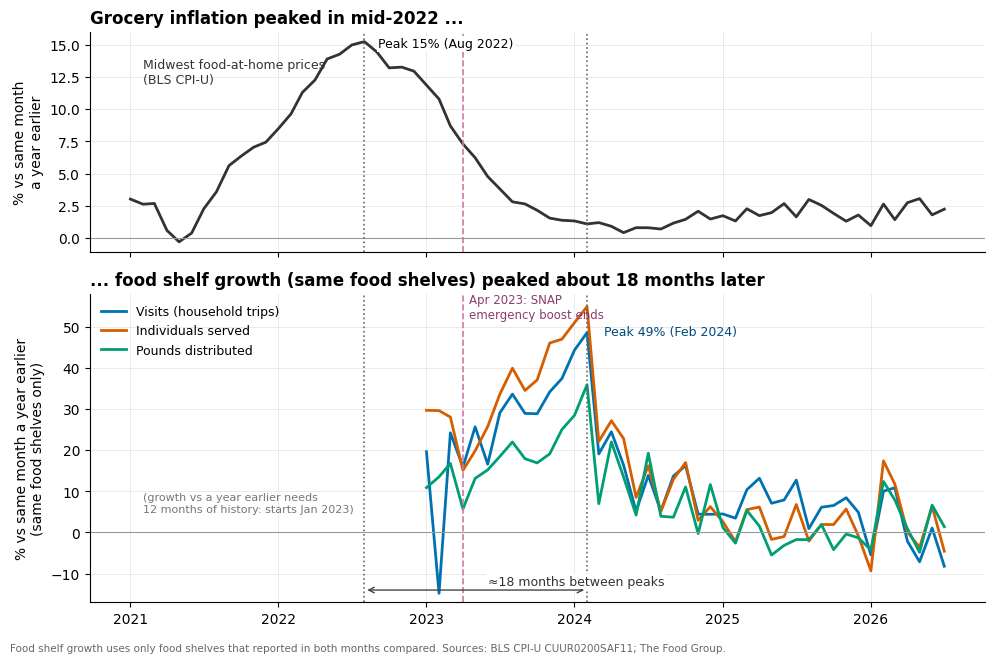

inflation peak Aug 2022 -> matched visits growth peak Feb 2024: 18 months


In [5]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6.6), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
p = infl.loc["2021-01":, "mw_food_home"]
a1.plot(p.index, p, color=COL["price"], lw=2)
a1.axhline(0, color="#999", lw=0.8)
a1.set_ylabel("% vs same month\na year earlier")
a1.set_title("Grocery inflation peaked in mid-2022 ...", loc="left")
a1.annotate(f"Peak {p.max():.0f}% ({p.idxmax():%b %Y})", xy=(p.idxmax(), p.max()), xytext=(10, -4),
            textcoords="offset points", fontsize=9, bbox=dict(facecolor="white", edgecolor="none", pad=1))
a1.text(pd.Timestamp("2021-02-01"), 12, "Midwest food-at-home prices\n(BLS CPI-U)", fontsize=9, color="#333")
for m in METRICS:
    a2.plot(Y.index, Y[m + "_yoy"], color=COL[m], lw=2, label=LABEL[m])
a2.axhline(0, color="#999", lw=0.8)
peak_v = Y["visits_yoy"].idxmax()
a2.set_title("... food shelf growth (same food shelves) peaked about 18 months later", loc="left")
a2.set_ylim(-17, 58)
a2.set_ylabel("% vs same month a year earlier\n(same food shelves only)")
a2.legend(loc="upper left", ncol=1, fontsize=9)
for ax in (a1, a2):
    ax.axvline(pd.Timestamp("2023-04-01"), color="#CC79A7", ls="--", lw=1.2)
    ax.axvline(p.idxmax(), color="#666", ls=":", lw=1.2)
    ax.axvline(peak_v, color="#666", ls=":", lw=1.2)
a2.annotate("", xy=(peak_v, -14), xytext=(p.idxmax(), -14), arrowprops=dict(arrowstyle="<->", color="#444"))
a2.text(pd.Timestamp("2023-06-01"), -12.8, "≈18 months between peaks", ha="left", fontsize=9, color="#333",
        bbox=dict(facecolor="white", edgecolor="none", pad=1))
a2.text(pd.Timestamp("2021-02-01"), 5, "(growth vs a year earlier needs\n12 months of history: starts Jan 2023)", fontsize=8, color="#777")
a2.text(pd.Timestamp("2023-04-15"), 52, "Apr 2023: SNAP\nemergency boost ends", color="#8a3d6e", fontsize=8.5)
a2.annotate(f"Peak {Y.loc[peak_v, 'visits_yoy']:.0f}% ({peak_v:%b %Y})", xy=(peak_v, Y.loc[peak_v, "visits_yoy"]),
            xytext=(12, -2), textcoords="offset points", fontsize=9, color="#004c7a")
a2.xaxis.set_major_locator(mdates.YearLocator()); a2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.text(0.01, 0.005, "Food shelf growth uses only food shelves that reported in both months compared. Sources: BLS CPI-U CUUR0200SAF11; The Food Group.",
         fontsize=7.5, color="#666")
plt.tight_layout(rect=(0, 0.02, 1, 1))
plt.savefig(FIG_DIR / "q4_1_inflation_vs_growth.png", dpi=200)
plt.show()
print(f"inflation peak {p.idxmax():%b %Y} -> matched visits growth peak {peak_v:%b %Y}: "
      f"{(peak_v.year - p.idxmax().year) * 12 + peak_v.month - p.idxmax().month} months")

**What the eye sees:** inflation peaked in **Aug 2022**; food shelf growth (same food shelves) stayed very high through 2023 and peaked in **Jan–Feb 2024** (Feb 2024's +49% is boosted by an unusually low Feb 2023), then fell to single digits in 2025 as inflation sat at 1–3%. There was **no jump at the moment prices spiked**. But the eye can be fooled: both lines just "go up then down" once, and the SNAP cut (pink line) lands in the middle. Steps 3–4 test this properly.

## Step 3 · Lag profile, compared against chance

For each delay *k* = 0…24 months: correlation between food shelf growth this month and food inflation *k* months earlier. Data: 43 months (Jan 2023 – Jul 2026).

**Why a special "chance" band:** YoY numbers overlap (Feb and Mar both share 11 of 12 months), so neighbouring months are near-copies, and *any two smooth hump-shaped series* correlate strongly at *some* delay. So we build **2,000 fake inflation series** with the same smoothness as the real one but humps at random times (*phase-randomised surrogates*), redo the whole lag profile on each, and ask: how often does the **best** delay for the fake series beat the real one? Taking the best of 25 delays is part of the test, so "picking the best lag" is paid for.

In [6]:
LAGS = np.arange(0, 25)
x_full = infl["mw_food_home"].loc["2019-01-01":].dropna()   # Jan 2020 - Jul 2026

def lag_profile(y, x, lags=LAGS):
    return np.array([y.corr(x.shift(k).reindex(y.index)) for k in lags])

rng = np.random.default_rng(2026)
def phase_surrogate(x):
    v = x.values; f = np.fft.rfft(v - v.mean())
    ph = rng.uniform(0, 2 * np.pi, len(f)); ph[0] = 0
    if len(v) % 2 == 0: ph[-1] = 0
    return pd.Series(np.fft.irfft(np.abs(f) * np.exp(1j * ph), len(v)) + v.mean(), index=x.index)

N_SURR = 2000
surr = [phase_surrogate(x_full) for _ in range(N_SURR)]
prof, null_pt, null_max, pval = {}, {}, {}, {}
for m in METRICS:
    y = Y[m + "_yoy"]
    prof[m] = lag_profile(y, x_full)
    S = np.array([lag_profile(y, s) for s in surr])
    null_pt[m] = np.quantile(S, 0.95, axis=0)
    null_max[m] = np.quantile(S.max(axis=1), 0.95)
    pval[m] = (np.sum(S.max(axis=1) >= prof[m].max()) + 1) / (N_SURR + 1)

lagtab = pd.DataFrame({m: {"best lag (months)": int(LAGS[prof[m].argmax()]), "corr at best lag": prof[m].max(),
                           "corr at lag 0": prof[m][0], "corr at lag 6": prof[m][6], "corr at lag 12": prof[m][12],
                           "chance threshold (best of 25 lags, 95%)": null_max[m],
                           "p-value (incl. picking best lag)": pval[m],
                           "lags beating chance threshold": ", ".join(map(str, LAGS[prof[m] > null_max[m]])) or "none"}
                       for m in METRICS}).T
lagtab

,best lag (months),corr at best lag,corr at lag 0,corr at lag 6,corr at lag 12,"chance threshold (best of 25 lags, 95%)",p-value (incl. picking best lag),lags beating chance threshold
visits,15,0.784366,-0.056138,0.327166,0.725805,0.791517,0.063968,none
individuals,15,0.889619,0.192476,0.532332,0.852152,0.866845,0.007996,"13, 14, 15"
pounds,15,0.828133,0.096556,0.42494,0.762735,0.81697,0.015992,15


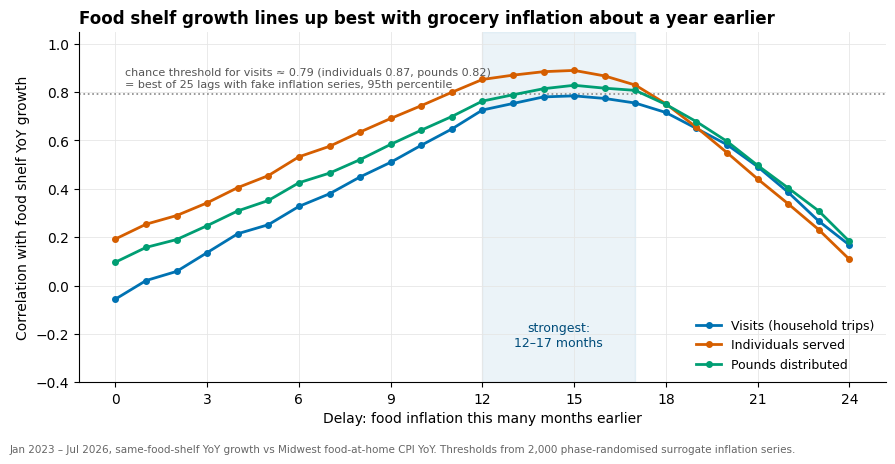

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.axhline(null_max["visits"], color="#888", ls=":", lw=1.2)
ax.text(0.3, null_max["visits"] + 0.02, f"chance threshold for visits ≈ {null_max['visits']:.2f} (individuals {null_max['individuals']:.2f}, pounds {null_max['pounds']:.2f})\n= best of 25 lags with fake inflation series, 95th percentile",
        fontsize=8, color="#555", va="bottom")
for m in METRICS:
    ax.plot(LAGS, prof[m], color=COL[m], lw=2, marker="o", ms=4, label=LABEL[m])
ax.axvspan(12, 17, color="#0072B2", alpha=0.08)
ax.text(14.5, -0.25, "strongest:\n12–17 months", ha="center", fontsize=9, color="#004c7a")
ax.set_xlabel("Delay: food inflation this many months earlier")
ax.set_ylabel("Correlation with food shelf YoY growth")
ax.set_ylim(-0.4, 1.05); ax.set_xticks(range(0, 25, 3))
ax.set_title("Food shelf growth lines up best with grocery inflation about a year earlier", loc="left")
ax.legend(loc="lower right", fontsize=9)
fig.text(0.01, 0.005, "Jan 2023 – Jul 2026, same-food-shelf YoY growth vs Midwest food-at-home CPI YoY. Thresholds from 2,000 phase-randomised surrogate inflation series.",
         fontsize=7.5, color="#666")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(FIG_DIR / "q4_2_lag_profile.png", dpi=200)
plt.show()

**Uncertainty on the delay itself (block bootstrap).** Resample the 43 months in blocks of 6 (keeps neighbouring months together), recompute the best lag each time.

**Placebo (time running backwards):** *future* inflation (leads) should not "predict" food shelf growth if the relationship is real; we report the best lead correlation for comparison.

In [8]:
def block_boot_best_lag(y, x, n=2000, block=6):
    X = np.column_stack([x.shift(k).reindex(y.index).values for k in LAGS]); yv = y.values; T = len(yv)
    out = []
    for _ in range(n):
        starts = rng.integers(0, T - block + 1, size=int(np.ceil(T / block)))
        idx = np.concatenate([np.arange(s, s + block) for s in starts])[:T]
        yy, XX = yv[idx], X[idx]
        c = [np.corrcoef(yy, XX[:, j])[0, 1] for j in range(len(LAGS))]
        out.append(LAGS[int(np.nanargmax(c))])
    return np.array(out)

boot = {m: block_boot_best_lag(Y[m + "_yoy"], x_full) for m in METRICS}
leads = {m: max(Y[m + "_yoy"].corr(x_full.shift(-k).reindex(Y.index)) for k in range(1, 13)) for m in METRICS}
pd.DataFrame({m: {"best lag": int(LAGS[prof[m].argmax()]), "bootstrap median": np.median(boot[m]),
                  "bootstrap 80% range": f"{np.quantile(boot[m], .1):.0f}–{np.quantile(boot[m], .9):.0f}",
                  "bootstrap 95% range": f"{np.quantile(boot[m], .025):.0f}–{np.quantile(boot[m], .975):.0f}",
                  "placebo: best corr with FUTURE inflation (1–12 mo ahead)": round(leads[m], 2)} for m in METRICS}).T

,best lag,bootstrap median,bootstrap 80% range,bootstrap 95% range,placebo: best corr with FUTURE inflation (1–12 mo ahead)
visits,15,14.0,12–17,12–20,-0.1
individuals,15,15.0,12–16,12–17,0.13
pounds,15,15.0,14–17,12–17,0.03


**Placebo: other prices.** If food shelf growth matches *any* price series that happened to hump in 2022, the food-price result is less special. We run the same lag profile on shelter, gasoline, energy, all items and restaurant prices (same surrogate test).

In [9]:
rows = []
for c in ["mw_food_home", "us_food_home", "msp_food_home", "mw_food_away", "mw_all_items", "mw_shelter", "mw_gasoline", "mw_energy"]:
    xc = infl[c].loc["2020-01-01":].dropna()
    y = Y["visits_yoy"]
    pr = lag_profile(y, xc)
    S = np.array([lag_profile(y, phase_surrogate(xc)) for _ in range(500)]).max(axis=1)
    rows.append({"price series": c, "peak date": f"{infl[c].loc['2021':].idxmax():%b %Y}",
                 "best lag": int(LAGS[pr.argmax()]), "corr": round(pr.max(), 2), "corr at lag 0": round(pr[0], 2),
                 "p (incl. picking lag)": round((np.sum(S >= pr.max()) + 1) / 501, 3)})
placebo_prices = pd.DataFrame(rows).set_index("price series")
placebo_prices

,peak date,best lag,corr,corr at lag 0,p (incl. picking lag)
price series,,,,,
mw_food_home,Aug 2022,15,0.78,-0.06,0.060
us_food_home,Aug 2022,14,0.78,-0.11,0.058
msp_food_home,Jul 2022,13,0.73,-0.23,0.174
mw_food_away,Oct 2022,11,0.74,0.20,0.104
mw_all_items,Jun 2022,18,0.79,-0.18,0.024
mw_shelter,Jul 2023,5,0.78,0.61,0.056
mw_gasoline,Apr 2021,20,0.70,-0.43,0.110
mw_energy,Jun 2022,20,0.71,-0.60,0.162


**Reading Step 3:**
- Same-month correlation is ≈ 0 (visits −0.06). **No immediate response.**
- The profile rises steadily and peaks at **15 months** for all three metrics; the block bootstrap puts the best lag at **12–17 months** (80% range), 12–20 (95%).
- Beating chance *including* the cost of picking the best lag: individuals p ≈ 0.01, pounds p ≈ 0.02, visits p ≈ 0.06 (borderline).
- Placebo: *future* inflation does not line up (best corr ≤ 0.13). Good.
- But **food prices are not uniquely special**: Midwest *all-items* inflation lines up just as well (lag 18, p ≈ 0.02), and shelter (which peaked a year later, in 2023) at lag 5. Grocery, housing and general prices all surged in 2021–23, so the honest reading is **"a broad cost-of-living squeeze, of which groceries are the most visible part"**. The data cannot separate them.

## Step 4 · Regression: delay chosen by a pre-stated rule, SNAP as a control

**Model (YoY form):** `food shelf YoY growth(t) = a + b × food inflation(t − k) [+ c × SNAP-cut window(t)] + error`
- YoY on both sides removes seasons and works with *rates of change*, not trending levels (levels would give a fake correlation: prices only rose and visits only rose).
- **SNAP control:** `ea_window` = 1 for Apr 2023 – Mar 2024, the months whose YoY comparison straddles the end of SNAP emergency allotments (Q5). A second version uses the YoY % change in SNAP benefit per person (data end Mar 2026).
- **Standard errors:** Newey–West (HAC, 12 lags), because neighbouring YoY months overlap.
- **How the delay k is chosen (stated before looking at the result):** (1) report the pre-set delays **0, 3, 6, 12** regardless; (2) pick k from 0–24 by **AIC/BIC** on the same 43 months; (3) **leave-one-year-out cross-validation**: fit on three calendar years, predict the fourth.

In [10]:
def yoy_fit(m, k, snap=None, data=None, price="mw_food_home", sample=None):
    d = (data if data is not None else Y).copy()
    if sample is not None: d = d.loc[sample[0]:sample[1]]
    d["x"] = infl[price].shift(k).reindex(d.index)
    cols = ["x"] + ([snap] if snap else [])
    d = d.dropna(subset=[m] + cols)
    return sm.OLS(d[m], sm.add_constant(d[cols])).fit(cov_type="HAC", cov_kwds={"maxlags": 12})

print("Correlation of SNAP-cut window with food inflation k months earlier:",
      {k: round(Y["ea_window"].corr(infl["mw_food_home"].shift(k).reindex(Y.index)), 2) for k in [0, 3, 6, 12, 15]})

rows = []
for m in METRICS:
    for k in [0, 3, 6, 12]:
        for snap in [None, "ea_window"]:
            r = yoy_fit(m + "_yoy", k, snap)
            rows.append({"metric": m, "lag": k, "SNAP control": snap or "none", "b (pts per 1 pt inflation)": r.params["x"],
                         "95% CI": f"{r.conf_int().loc['x', 0]:.2f} to {r.conf_int().loc['x', 1]:.2f}",
                         "p": r.pvalues["x"], "SNAP window effect (pts)": r.params.get("ea_window", np.nan),
                         "SNAP p": r.pvalues.get("ea_window", np.nan), "R2": r.rsquared, "AIC": r.aic})
pre_set = pd.DataFrame(rows).set_index(["metric", "lag", "SNAP control"])
pre_set.round(3)

Correlation of SNAP-cut window with food inflation k months earlier: {0: 0.08, 3: 0.32, 6: 0.52, 12: 0.87, 15: 0.83}


b (pts per 1 pt inflation)         95% CI      p  SNAP window effect (pts)  SNAP p     R2      AIC
metric      lag SNAP control                                                                                                    
visits      0   none                              -0.306  -1.49 to 0.88  0.612                       NaN     NaN  0.003  351.655
                ea_window                         -0.634  -1.70 to 0.43  0.242                    23.445   0.000  0.580  316.521
            3   none                               0.513  -0.42 to 1.45  0.283                       NaN     NaN  0.019  350.986
                ea_window                         -0.438  -1.14 to 0.26  0.219                    24.305   0.000  0.578  316.656
            6   none                               0.970  -0.05 to 1.99  0.061                       NaN     NaN  0.107  346.922
                ea_window                         -0.249  -0.85 to 0.35  0.414                    24.499   0.000  0.571  317.358
            12  none                               1.928   1.20 to 2.66  0.000                       NaN     NaN  0.527  319.617
                ea_window                          0.766  -0.04 to 1.58  0.064                    15.401   0.000  0.586  315.882
individuals 0   none                               1.265  -0.52 to 3.05  0.165                       NaN     NaN  0.037  366.205
                ea_window                          0.884  -1.02 to 2.78  0.362                    27.221   0.000  0.572  333.308
            3   none                               1.553   0.46 to 2.65  0.005                       NaN     NaN  0.117  362.478
                ea_window                          0.526  -0.85 to 1.91  0.455                    26.240   0.000  0.566  333.899
            6   none                               1.903   0.85 to 2.96  0.000                       NaN     NaN  0.283  353.500
                ea_window                          0.720  -0.44 to 1.88  0.223                    23.754   0.002  0.584  332.109
            12  none                               2.728   2.00 to 3.45  0.000                       NaN     NaN  0.726  312.133
                ea_window                          2.731   2.15 to 3.31  0.000                    -0.050   0.994  0.726  314.133
pounds      0   none                               0.380  -0.69 to 1.45  0.488                       NaN     NaN  0.009  323.229
                ea_window                          0.182  -0.92 to 1.28  0.747                    14.155   0.000  0.414  302.663
            3   none                               0.672   0.02 to 1.32  0.043                       NaN     NaN  0.061  320.912
                ea_window                          0.129  -0.60 to 0.85  0.728                    13.900   0.000  0.414  302.671
            6   none                               0.908   0.28 to 1.54  0.005                       NaN     NaN  0.181  315.068
                ea_window                          0.272  -0.32 to 0.87  0.371                    12.775   0.000  0.424  301.939
            12  none                               1.460   1.04 to 1.88  0.000                       NaN     NaN  0.582  286.148
                ea_window                          1.638   1.07 to 2.20  0.000                    -2.352   0.353  0.584  287.875

In [11]:
def loyo_cv(m, k, snap=None):
    d = Y.copy(); d["x"] = infl["mw_food_home"].shift(k).reindex(d.index)
    cols = ["x"] + ([snap] if snap else []); err = []
    for yr in d.index.year.unique():
        tr, te = d[d.index.year != yr], d[d.index.year == yr]
        if snap and tr[snap].std() == 0:
            return np.nan
        f = sm.OLS(tr[m], sm.add_constant(tr[cols])).fit()
        err.append(((te[m] - f.predict(sm.add_constant(te[cols], has_constant="add"))) ** 2).values)
    return np.sqrt(np.concatenate(err).mean())

sel = []
for m in METRICS:
    for snap in [None, "ea_window"]:
        fits = {k: yoy_fit(m + "_yoy", k, snap) for k in LAGS}
        aic = pd.Series({k: f.aic for k, f in fits.items()}); bic = pd.Series({k: f.bic for k, f in fits.items()})
        cv = pd.Series({k: loyo_cv(m + "_yoy", k, snap) for k in LAGS})
        kb = int(aic.idxmin()); f = fits[kb]
        near = aic[aic <= aic.min() + 2].index   # lags within 2 AIC points = statistically indistinguishable
        sel.append({"metric": m, "SNAP control": snap or "none", "AIC lag": kb, "BIC lag": int(bic.idxmin()),
                    "CV lag": int(cv.idxmin()), "lags within 2 AIC": f"{near.min()}–{near.max()}",
                    "b at AIC lag": f.params["x"], "b 95% CI": f"{f.conf_int().loc['x', 0]:.2f} to {f.conf_int().loc['x', 1]:.2f}",
                    "SNAP window effect": f.params.get("ea_window", np.nan), "SNAP p": f.pvalues.get("ea_window", np.nan)})
lag_select = pd.DataFrame(sel).set_index(["metric", "SNAP control"])
lag_select.round(2)

AIC lag  BIC lag  CV lag lags within 2 AIC  b at AIC lag      b 95% CI  SNAP window effect  SNAP p
metric      SNAP control                                                                                                    
visits      none               15       15      15             14–16          2.12  1.62 to 2.62                 NaN     NaN
            ea_window          17       17      23             16–18          1.22  0.66 to 1.79               13.51    0.00
individuals none               15       15      15             14–15          2.90  2.66 to 3.13                 NaN     NaN
            ea_window          15       15      14             14–15          2.83  1.48 to 4.18                0.91    0.92
pounds      none               15       15      16             15–15          1.61  1.44 to 1.78                 NaN     NaN
            ea_window          15       15      15             14–15          1.84  1.39 to 2.29               -3.13    0.31

**Read this table carefully.** The SNAP-cut window and inflation ~12–15 months earlier are **almost the same thing** in time (correlation ≈ 0.85), because the inflation spike (spring–autumn 2022) came about a year before the SNAP cut's effect window (Apr 2023 – Mar 2024). With one episode, the data cannot cleanly split credit between them. We report both models and treat the inflation effect as a **range**.

**SNAP benefit per person (continuous), sample to Mar 2026:**

In [12]:
rows = []
for m in METRICS:
    for k in [12, int(lag_select.loc[(m, "none"), "AIC lag"])]:
        r = yoy_fit(m + "_yoy", k, "snap_benefit_yoy", sample=("2023-01-01", "2026-03-01"))
        rows.append({"metric": m, "lag": k, "b inflation": r.params["x"], "p": r.pvalues["x"],
                     "b SNAP benefit YoY %": r.params["snap_benefit_yoy"], "p SNAP": r.pvalues["snap_benefit_yoy"], "n": int(r.nobs)})
pd.DataFrame(rows).set_index(["metric", "lag"]).round(3)

b inflation      p  b SNAP benefit YoY %  p SNAP   n
metric      lag                                                      
visits      12         0.957  0.002                -0.333   0.000  39
            15         1.314  0.000                -0.268   0.000  39
individuals 12         2.612  0.000                -0.009   0.946  39
            15         2.823  0.000                -0.001   0.996  39
pounds      12         1.523  0.000                 0.039   0.491  39
            15         1.772  0.000                 0.072   0.316  39

**Reading Step 4:**
- All three lag-choice rules (AIC, BIC, leave-one-year-out CV) pick **≈15 months** without the SNAP control; with it, 15 (individuals, pounds) and 17 (visits). The pre-set lags 0, 3 and 6 are never significant once SNAP is in.
- **Size (b):** each 1 percentage point of food inflation ~15 months earlier goes with ≈ **1.2–2.9 points** more YoY growth at the same food shelves (visits ≈ 1.2 with SNAP control to 2.1 without; individuals ≈ 2.8–2.9; pounds ≈ 1.6–1.8). Treat these as **upper bounds**: the 2022 price spike coincided with the end of other pandemic supports and post-COVID recovery of food shelf use, which this model cannot separate.
- **SNAP control:** individuals and pounds keep their full effect; visits keeps about half. Using SNAP benefit per person instead of the window gives the same picture (visits b ≈ 1.0–1.3, still p < 0.01).

### Step 4b · Is there an *immediate* response? (month-to-month model)

YoY growth is smooth by construction, so it can't show a 1–2 month response well. Here: monthly % change of each metric (per reporting site) on food inflation in the last 0–2, 3–5, 6–8, 9–11 months (quarter blocks), with month-of-year dummies (seasons) and the SNAP window. Number of blocks chosen by BIC.

In [13]:
pi_m = np.log(cpi["mw_food_home"]).diff() * 100
D = pd.DataFrame(index=state.index)
BLOCKS = [(0, 2), (3, 5), (6, 8), (9, 11)]
for a, b in BLOCKS:
    D[f"infl_{a}_{b}"] = sum(pi_m.shift(k) for k in range(a, b + 1)).reindex(D.index)
D["ea_window"] = state["ea_window"]; D["moy"] = D.index.month.astype(str)
mm_rows = []
for m in METRICS:
    D["dlog"] = np.log(state[m + "_per_site"]).diff() * 100
    d = D.dropna()
    best = None
    for nb in range(0, 5):
        terms = [f"infl_{a}_{b}" for a, b in BLOCKS[:nb]]
        r = smf.ols("dlog ~ C(moy) + ea_window" + "".join(" + " + t for t in terms), d).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
        if best is None or r.bic < best[1].bic: best = (nb, r)
        if nb == 4: full = r
    terms4 = [f"infl_{a}_{b}" for a, b in BLOCKS]
    mm_rows.append({"metric": m, "BIC picks # of inflation blocks": best[0],
                    **{f"{t} (p)": f"{full.params[t]:.2f} ({full.pvalues[t]:.2f})" for t in terms4},
                    "joint test all blocks = 0, p": float(full.f_test(", ".join(f"{t} = 0" for t in terms4)).pvalue)})
pd.DataFrame(mm_rows).set_index("metric")

,BIC picks # of inflation blocks,infl_0_2 (p),infl_3_5 (p),infl_6_8 (p),infl_9_11 (p),"joint test all blocks = 0, p"
metric,,,,,,
visits,0,0.42 (0.66),-0.48 (0.70),0.75 (0.57),-0.48 (0.63),0.952368
individuals,0,1.80 (0.04),-2.26 (0.02),1.10 (0.31),0.11 (0.87),0.121802
pounds,0,0.40 (0.59),-1.01 (0.28),0.63 (0.47),-0.05 (0.94),0.835460


**Reading 4b:** BIC keeps **no** inflation terms for any metric; jointly, the last 0–11 months of inflation add nothing to month-to-month changes (visits p ≈ 0.95, pounds ≈ 0.84, individuals ≈ 0.12). Month-to-month data are noisy, but there is **no sign of a quick (0–3 month) response**.

## Step 5 · Do all three metrics respond?

In [14]:
cmp = pd.DataFrame({m: {
    "YoY growth 2023 (avg)": Y.loc["2023", m + "_yoy"].mean(), "YoY growth 2024": Y.loc["2024", m + "_yoy"].mean(),
    "YoY growth 2025": Y.loc["2025", m + "_yoy"].mean(), "YoY growth 2026 (Jan-Jul)": Y.loc["2026", m + "_yoy"].mean(),
    "best lag": int(LAGS[prof[m].argmax()]), "corr at best lag": prof[m].max(),
    "b at lag 12, no SNAP control": pre_set.loc[(m, 12, "none"), "b (pts per 1 pt inflation)"],
    "b at lag 12, with SNAP control": pre_set.loc[(m, 12, "ea_window"), "b (pts per 1 pt inflation)"],
    "p at lag 12, with SNAP control": pre_set.loc[(m, 12, "ea_window"), "p"]} for m in METRICS}).round(2)
ratio = pd.DataFrame({"pounds per visit": state["pounds"] / state["visits"],
                      "people per visit": state["individuals"] / state["visits"]})
print(ratio.groupby(ratio.index.year).mean().round(2))
cmp

       pounds per visit  people per visit
month                                    
2022              60.82              2.87
2023              56.55              3.07
2024              54.37              3.14
2025              50.17              3.00
2026              50.86              3.09


,visits,individuals,pounds
YoY growth 2023 (avg),23.30,32.22,16.24
YoY growth 2024,18.01,20.61,13.39
YoY growth 2025,7.20,1.91,-0.87
YoY growth 2026 (Jan-Jul),-0.13,2.59,2.90
best lag,15.00,15.00,15.00
corr at best lag,0.78,0.89,0.83
"b at lag 12, no SNAP control",1.93,2.73,1.46
"b at lag 12, with SNAP control",0.77,2.73,1.64
"p at lag 12, with SNAP control",0.06,0.00,0.00


**Reading:** all three metrics rose and fell with inflation ~15 months earlier, and none responded in the same month.
- **Individuals** track it most tightly (corr 0.89) and keep the full effect with the SNAP control.
- **Pounds** grew the least (smallest b): pounds per visit fell from ≈61 lb (2022) to ≈50 lb (2025–26). Pounds depend on what food shelves *have* to give (food bank stock, donations, TEFAP), so they measure supply as well as demand: when demand rose, each visit got less food.
- **Visits** carry the clearest SNAP-cut signal: adding the SNAP control cuts the visits inflation effect by more than half (1.9 → 0.8 at lag 12; 2.1 → 1.2 at the AIC lag), while for individuals and pounds the SNAP window adds nothing once inflation is in.

## Step 6 · Other cycles that prices don't explain

Prices move slowly (inflation changes over many months), so they cannot explain month-to-month seasonal swings. We measure seasons on **per-reporting-site** values (removes network growth):
- **Seasonal index:** each month ÷ the centred 12-month average around it (100 = typical month).
- **STL decomposition** (trend + season + leftover) on log values, to find unusual months.
- **Calendar:** number of weekdays in the month. **Summer:** children's share of individuals.

In [15]:
seas = {}
for m in METRICS:
    s = state[m + "_per_site"]
    ma = s.rolling(12, center=True).mean().rolling(2, center=True).mean().shift(-1)   # centred 2x12 MA
    seas[m] = (s / ma * 100)
seas = pd.DataFrame(seas)
idx = seas.groupby(seas.index.month).agg(["mean", "std", "count"])
season_idx = pd.DataFrame({m: idx[(m, "mean")] for m in METRICS}).round(1)
season_idx.index = pd.to_datetime(season_idx.index, format="%m").strftime("%b")
season_idx["n years"] = idx[("visits", "count")].values
season_idx.T

month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
visits,98.4,96.8,99.6,101.8,99.7,98.7,101.8,105.4,99.2,103.4,102.0,91.6
individuals,99.5,96.4,101.5,102.4,99.4,97.8,100.4,103.8,97.3,103.2,102.7,91.2
pounds,99.1,92.9,98.5,99.1,100.0,97.2,99.8,105.6,96.3,104.6,104.5,98.6
n years,4.0,3.0,3.0,3.0,3.0,3.0,4.0,4.0,4.0,4.0,4.0,4.0


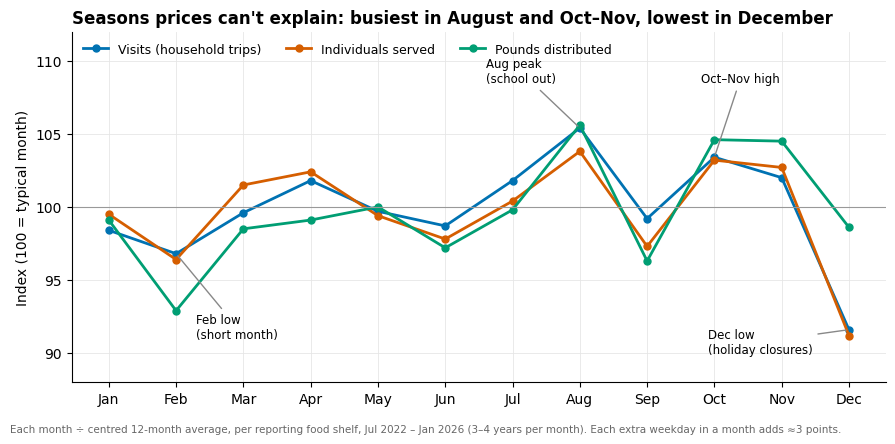

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.4))
xm = np.arange(12)
for i, m in enumerate(METRICS):
    ax.plot(xm, season_idx[m], color=COL[m], lw=2, marker="o", ms=5, label=LABEL[m])
ax.axhline(100, color="#999", lw=0.8)
ax.set_xticks(xm, season_idx.index)
ax.set_ylabel("Index (100 = typical month)")
ax.annotate("Aug peak\n(school out)", xy=(7, season_idx.loc["Aug", "visits"]), xytext=(5.6, 108.5), fontsize=8.5,
            arrowprops=dict(arrowstyle="-", color="#888"))
ax.annotate("Oct–Nov high", xy=(9, season_idx.loc["Oct", "visits"]), xytext=(8.8, 108.5), fontsize=8.5, arrowprops=dict(arrowstyle="-", color="#888"))
ax.annotate("Dec low\n(holiday closures)", xy=(11, season_idx.loc["Dec", "visits"]), xytext=(8.9, 90.0), fontsize=8.5,
            arrowprops=dict(arrowstyle="-", color="#888"))
ax.annotate("Feb low\n(short month)", xy=(1, season_idx.loc["Feb", "visits"]), xytext=(1.3, 91.0), fontsize=8.5,
            arrowprops=dict(arrowstyle="-", color="#888"))
ax.set_title("Seasons prices can't explain: busiest in August and Oct–Nov, lowest in December", loc="left")
ax.legend(loc="upper left", fontsize=9, ncol=3)
ax.set_ylim(88, 112)
fig.text(0.01, 0.005, "Each month ÷ centred 12-month average, per reporting food shelf, Jul 2022 – Jan 2026 (3–4 years per month). Each extra weekday in a month adds ≈3 points.",
         fontsize=7.5, color="#666")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(FIG_DIR / "q4_3_seasonal_profile.png", dpi=200)
plt.show()

In [17]:
# calendar: weekdays per month, after removing each calendar month's average seasonal level
cal = seas.copy()
cal["weekdays"] = [np.busday_count(d.date(), (d + pd.offsets.MonthBegin(1)).date()) for d in cal.index]
for m in METRICS:
    cal[m + "_dev"] = cal[m] - cal.groupby(cal.index.month)[m].transform("mean")
cal["wd_dev"] = cal["weekdays"] - cal.groupby(cal.index.month)["weekdays"].transform("mean")
c = cal.dropna(subset=["visits_dev"])
wd = {m: sm.OLS(c[m + "_dev"], sm.add_constant(c["wd_dev"])).fit(cov_type="HAC", cov_kwds={"maxlags": 3}) for m in METRICS}
print("Extra weekday in a month (vs same month other years) -> index points:",
      {m: f"{wd[m].params['wd_dev']:+.2f} (p={wd[m].pvalues['wd_dev']:.2f})" for m in METRICS})

kids = (state["children"] / state["individuals"] * 100)
kid_m = kids.groupby(kids.index.month).mean()
print(f"Children share of individuals: Jun-Aug avg {kid_m.loc[[6, 7, 8]].mean():.1f}% vs Sep-May avg {kid_m.drop([6, 7, 8]).mean():.1f}%")
print("By month:", kid_m.round(1).to_dict())

Extra weekday in a month (vs same month other years) -> index points: {'visits': '+2.97 (p=0.00)', 'individuals': '+2.91 (p=0.00)', 'pounds': '+3.16 (p=0.00)'}
Children share of individuals: Jun-Aug avg 36.4% vs Sep-May avg 35.5%
By month: {1: 36.1, 2: 35.6, 3: 35.2, 4: 35.3, 5: 35.7, 6: 36.1, 7: 36.3, 8: 36.7, 9: 35.3, 10: 35.4, 11: 35.3, 12: 35.8}


In [18]:
stl_rows = {}
for m in METRICS:
    r = STL(np.log(state[m + "_per_site"]), period=12, robust=True).fit()
    stl_rows[m] = r.resid * 100
resid = pd.DataFrame(stl_rows)
print("Largest unusual months (STL leftover, % above/below expected, per reporting site):")
big = resid.abs().max(axis=1).sort_values(ascending=False).head(8).index
resid.loc[big].round(1).sort_index()

Largest unusual months (STL leftover, % above/below expected, per reporting site):


,visits,individuals,pounds
month,,,
2023-02-01,-30.7,-2.7,-5.1
2023-04-01,-6.9,-11.1,-13.2
2023-12-01,14.5,13.2,2.2
2024-01-01,24.7,17.0,16.0
2024-02-01,0.2,18.9,13.7
2025-01-01,14.0,0.4,7.9
2025-07-01,11.5,7.4,2.1
2026-01-01,0.1,-21.8,0.1


**Other patterns found** (details in the explainer):
- **August is the busiest month** (≈+5% vs a typical month), with the children's share of people served highest in Jul–Aug (school meals stop); **September dips** (school meals restart).
- **October–November are high**; **December is the lowest month** (≈−8% visits) even though it has a normal number of weekdays: holiday closures and seasonal holiday giving elsewhere.
- **February is low** mostly because it is short: each extra weekday in a month adds ≈3 index points (p < 0.01) for all three metrics. Calendar length matters.
- **Unusual one-off months** (STL leftovers): Feb 2023 visits (−31%, a reporting quirk: Feb 2022 visits look too high), the Dec 2023 – Feb 2024 surge (+14 to +25%, the post-SNAP-cut / high-price peak), Jan 2025, Jul 2025, and **Jan 2026 individuals −22%** (the early-2026 metro immigration-enforcement period; families may have avoided going out, then Feb–Mar 2026 rebounded). None of these come from grocery prices.

## Step 7 · Robustness

Same headline numbers (best lag, correlation at that lag, and b at lag 12 with the SNAP control) under different choices.

In [19]:
def summarize(y, price="mw_food_home", label=""):
    xp = infl[price].loc["2019-01-01":].dropna()
    pr = lag_profile(y.dropna(), xp)
    d = pd.DataFrame({"y": y}).dropna(); d["ea_window"] = Y["ea_window"]
    r = yoy_fit("y", 12, "ea_window", data=d, price=price)
    r0 = yoy_fit("y", 12, None, data=d, price=price)
    return {"check": label, "months": len(d), "best lag": int(LAGS[np.nanargmax(pr)]), "corr at best lag": round(np.nanmax(pr), 2),
            "b lag12 (no SNAP)": round(r0.params["x"], 2), "b lag12 (+SNAP)": round(r.params["x"], 2), "p (+SNAP)": round(r.pvalues["x"], 3)}

site_noflag = site_nm[~site_nm[FLAGS].any(axis=1)]
site_fsonly = site_nm[site_nm["site_group"] == "food_shelf"]
rob = []
for m in METRICS:
    base = Y[m + "_yoy"]
    rob += [summarize(base, label=f"{m}: BASE (matched sites, Midwest food at home)"),
            summarize(Y[m + "_yoy_all"], label=f"{m}: all sites (raw totals)"),
            summarize(Y[m + "_yoy_persite"], label=f"{m}: per reporting site"),
            summarize(base, "us_food_home", f"{m}: U.S. food-at-home CPI"),
            summarize(base, "msp_food_home", f"{m}: Minneapolis-St. Paul food-at-home CPI"),
            summarize(base, "mw_all_items", f"{m}: Midwest ALL-items CPI"),
            summarize(matched_yoy(site_noflag, m)["yoy"].reindex(Y.index), label=f"{m}: drop flagged rows"),
            summarize(matched_yoy(site_fsonly, m)["yoy"].reindex(Y.index), label=f"{m}: food_shelf sites only (no outreach)")]
    d24 = Y.loc["2024-01-01":, m + "_yoy"]
    xp = infl["mw_food_home"].loc["2019-01-01":]
    pr = lag_profile(d24, xp)
    r = yoy_fit(m + "_yoy", 12, None, sample=("2024-01-01", "2026-07-01"))
    rob.append({"check": f"{m}: 2024+ only (drops 2023 YoY, which compares with post-COVID 2022)", "months": len(d24),
                "best lag": int(LAGS[np.nanargmax(pr)]), "corr at best lag": round(np.nanmax(pr), 2),
                "b lag12 (no SNAP)": round(r.params["x"], 2), "b lag12 (+SNAP)": np.nan, "p (+SNAP)": np.nan})
robust = pd.DataFrame(rob).set_index("check")
robust

,months,best lag,corr at best lag,b lag12 (no SNAP),b lag12 (+SNAP),p (+SNAP)
check,,,,,,
"visits: BASE (matched sites, Midwest food at home)",43,15,0.78,1.93,0.77,0.064
visits: all sites (raw totals),43,14,0.80,2.19,1.53,0.000
visits: per reporting site,43,17,0.72,1.38,-0.16,0.786
visits: U.S. food-at-home CPI,43,14,0.78,2.24,1.01,0.044
visits: Minneapolis-St. Paul food-at-home CPI,43,13,0.73,1.72,0.49,0.280
visits: Midwest ALL-items CPI,43,18,0.79,3.37,0.16,0.795
visits: drop flagged rows,43,15,0.80,2.03,0.96,0.009
visits: food_shelf sites only (no outreach),43,15,0.78,1.94,0.76,0.095
"visits: 2024+ only (drops 2023 YoY, which compares with post-COVID 2022)",31,12,0.81,3.36,NaN,NaN


**Reading Step 7:** the **delay (12–18 months) survives every check**: raw totals, per-site, matched sites, U.S. or Minneapolis–St. Paul prices, dropping flagged rows, food-shelf-only sites, and dropping 2023 (lag 12, corr ≈ 0.8 on 2024–26 only). The **size with the SNAP control** is solid for individuals and pounds, but **fragile for visits** (p from <0.01 to 0.8 depending on the version; it vanishes per reporting site and with all-items CPI). Bottom line: timing is robust, the visits-specific price effect beyond the SNAP cut is not.

## Step 8 · Do some counties respond more? (county panel)

Prices are the **same statewide number** for every county, so a county panel **cannot** measure the price effect itself (month fixed effects soak it up). It can only test whether the response is **bigger in some kinds of counties**: `county YoY visit growth (matched sites) ~ county FE + month FE + inflation(t−12) × county trait`. Traits (standardised, 1 = one standard deviation): % rural (Census 2020), poverty rate (ACS 2024), % of food-insecure people earning too much for SNAP (Map the Meal Gap 2024). Weighted by last year's visits; standard errors clustered by county. Counties with < 100 matched visits last year in that month dropped (tiny counties swing wildly).

In [20]:
cm = matched_yoy(site_nm, "visits", by="fips").reset_index()
cm = cm[(cm["ly"] >= 100) & (cm["month"] >= "2023-01-01")]
rural = pd.read_csv(PROCESSED / "rural_share_2020_clean.csv", dtype={"fips": str})[["fips", "pct_rural_2020"]]
pov = (pd.read_csv(PROCESSED / "poverty_2022_2024_clean.csv", dtype={"county_geoid": str})
       .rename(columns={"county_geoid": "fips"}).query("year == 2024")[["fips", "poverty_rate"]])
mmg = pd.read_csv(PROCESSED / "mmg_mn_county_2022_2024.csv", dtype={"fips": str}).query("year == 2024")[["fips", "pct_fi_above_snap_threshold"]]
cm = cm.merge(rural, on="fips").merge(pov, on="fips").merge(mmg, on="fips")
cm["infl12"] = cm["month"].map(infl["mw_food_home"].shift(12))
cm["yoy_w"] = cm["yoy"].clip(cm["yoy"].quantile(0.01), cm["yoy"].quantile(0.99))
het = []
for trait in ["pct_rural_2020", "poverty_rate", "pct_fi_above_snap_threshold"]:
    cm["z"] = (cm[trait] - cm.groupby("fips")[trait].first().mean()) / cm.groupby("fips")[trait].first().std()
    r = smf.wls("yoy_w ~ C(fips) + C(month) + infl12:z", cm, weights=cm["ly"]).fit(cov_type="cluster", cov_kwds={"groups": cm["fips"]})
    het.append({"county trait (1 SD higher)": trait, "extra response per 1 pt inflation (pts)": r.params["infl12:z"],
                "95% CI": f"{r.conf_int().loc['infl12:z', 0]:.2f} to {r.conf_int().loc['infl12:z', 1]:.2f}", "p": r.pvalues["infl12:z"]})
print("county-months:", len(cm), "| counties:", cm["fips"].nunique())
pd.DataFrame(het).set_index("county trait (1 SD higher)").round(3)

county-months: 3263 | counties: 83


,extra response per 1 pt inflation (pts),95% CI,p
county trait (1 SD higher),,,
pct_rural_2020,0.053,-0.60 to 0.70,0.873
poverty_rate,-0.946,-2.00 to 0.11,0.078
pct_fi_above_snap_threshold,0.965,-0.05 to 1.98,0.063


**Reading Step 8:** rural and urban counties respond **about the same** (p ≈ 0.9). Two suggestive (p ≈ 0.06–0.08, not conclusive) patterns: counties where more food-insecure people **earn too much for SNAP** respond a bit *more* to prices (these households have no SNAP cushion), and higher-poverty counties a bit *less*. Worth a sentence, not a headline.

## Step 9 · Answer

In [21]:
best_v = int(lag_select.loc[("visits", "none"), "AIC lag"])
key = {
    "Midwest food-at-home inflation peak": f"{infl['mw_food_home'].max():.1f}% ({infl['mw_food_home'].idxmax():%b %Y})",
    "Same-food-shelf visit growth peak": f"{Y['visits_yoy'].max():+.0f}% ({Y['visits_yoy'].idxmax():%b %Y})",
    "Correlation at lag 0 (visits / individuals / pounds)": " / ".join(f"{prof[m][0]:+.2f}" for m in METRICS),
    "Best lag, months (visits / individuals / pounds)": " / ".join(str(int(LAGS[prof[m].argmax()])) for m in METRICS),
    "Correlation at best lag": " / ".join(f"{prof[m].max():.2f}" for m in METRICS),
    "p-value incl. picking the best lag (surrogates)": " / ".join(f"{pval[m]:.3f}" for m in METRICS),
    "Bootstrap 80% range of best lag (visits)": f"{np.quantile(boot['visits'], .1):.0f}–{np.quantile(boot['visits'], .9):.0f} months",
    "AIC-chosen lag, no SNAP control / with SNAP control (visits)":
        f"{lag_select.loc[('visits', 'none'), 'AIC lag']} / {lag_select.loc[('visits', 'ea_window'), 'AIC lag']}",
    "b at lag 12: visits no SNAP -> with SNAP": f"{pre_set.loc[('visits', 12, 'none'), 'b (pts per 1 pt inflation)']:.2f} -> {pre_set.loc[('visits', 12, 'ea_window'), 'b (pts per 1 pt inflation)']:.2f}",
    "b at lag 12: individuals no SNAP -> with SNAP": f"{pre_set.loc[('individuals', 12, 'none'), 'b (pts per 1 pt inflation)']:.2f} -> {pre_set.loc[('individuals', 12, 'ea_window'), 'b (pts per 1 pt inflation)']:.2f}",
    "b at lag 12: pounds no SNAP -> with SNAP": f"{pre_set.loc[('pounds', 12, 'none'), 'b (pts per 1 pt inflation)']:.2f} -> {pre_set.loc[('pounds', 12, 'ea_window'), 'b (pts per 1 pt inflation)']:.2f}",
}
pd.Series(key, name="value").to_frame()

,value
Midwest food-at-home inflation peak,15.2% (Aug 2022)
Same-food-shelf visit growth peak,+49% (Feb 2024)
Correlation at lag 0 (visits / individuals / pounds),-0.06 / +0.19 / +0.10
"Best lag, months (visits / individuals / pounds)",15 / 15 / 15
Correlation at best lag,0.78 / 0.89 / 0.83
p-value incl. picking the best lag (surrogates),0.064 / 0.008 / 0.016
Bootstrap 80% range of best lag (visits),12–17 months
"AIC-chosen lag, no SNAP control / with SNAP control (visits)",15 / 17
b at lag 12: visits no SNAP -> with SNAP,1.93 -> 0.77
b at lag 12: individuals no SNAP -> with SNAP,2.73 -> 2.73


**What this means for the next year (using only data through July 2026).** Grocery inflation has stayed near **2%** (1.0–3.1% a month-by-month YoY) through July 2026, about the same as late 2025, so **groceries alone point to no extra surge in 2027**. The watch item is **overall prices**: Midwest all-items inflation rose from 2.4% (Jan 2026) to 5.0% (May 2026) on a gasoline spike (+45% YoY in May). All-items inflation lined up with food shelf growth as well as food prices did (lag ≈ 18 months), so if it stays high, The Food Group should warn food shelves and donors to expect **above-normal growth from roughly mid-2027**.

In [22]:
recent = infl.loc["2025-07-01":"2026-07-01", ["mw_food_home", "mw_all_items", "mw_gasoline"]].round(1)
base_late25 = infl.loc["2025-07-01":"2025-12-01", "mw_food_home"].mean()
spring26 = infl.loc["2026-03-01":"2026-07-01", "mw_food_home"].mean()
lo, hi = lag_select.loc[("visits", "ea_window"), "b at AIC lag"], lag_select.loc[("individuals", "none"), "b at AIC lag"]
print(f"food inflation: H2-2025 avg {base_late25:.1f}% -> Mar-Jul 2026 avg {spring26:.1f}% (+{spring26 - base_late25:.1f} pts)")
print(f"implied extra YoY growth ~12-17 months later (b = {lo:.1f} to {hi:.1f}): "
      f"+{(spring26 - base_late25) * lo:.1f} to +{(spring26 - base_late25) * hi:.1f} pts, roughly Mar-Dec 2027 (upper bound)")
recent.T

food inflation: H2-2025 avg 2.0% -> Mar-Jul 2026 avg 2.3% (+0.2 pts)
implied extra YoY growth ~12-17 months later (b = 1.2 to 2.9): +0.3 to +0.6 pts, roughly Mar-Dec 2027 (upper bound)


date,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01
series,,,,,,,,,,,,,
mw_food_home,1.6,3.0,2.5,1.9,1.3,1.8,1.0,2.6,1.4,2.7,3.1,1.8,2.2
mw_all_items,2.6,2.8,3.1,3.0,3.0,2.7,2.4,2.8,3.4,4.1,5.0,3.8,3.5
mw_gasoline,-12.0,-8.6,-1.9,-5.0,1.0,-6.7,-11.2,-7.6,15.4,24.1,45.0,26.6,23.1


## Slide-ready section

**Charts (`outputs/q4/`):**
1. ⭐ `q4_1_inflation_vs_growth.png`: inflation peaked Aug 2022; food shelf growth at the same food shelves peaked ~18 months later.
2. `q4_2_lag_profile.png`: the best match is inflation ~15 months earlier (12–17); no same-month response.
3. `q4_3_seasonal_profile.png`: the seasons prices don't explain.

**Three sentences:**
1. *When grocery prices rise faster, more people come to food shelves, but not at once: growth at the same food shelves lines up best with grocery inflation about **15 months earlier** (likely range 12–17 months) and shows no same-month jump.*
2. *All three metrics follow this pattern: individuals most closely, pounds least (pounds per visit fell from 61 to 50 lb, so each visit got less food). Part of the 2023–24 surge is shared with the April 2023 SNAP cut, which hit at the same time, so the size of the price effect is a range, not one number.*
3. *Seasons are separate from prices: August and Oct–Nov are busiest and December the quietest, and longer months are busier. So when grocery inflation picks up, The Food Group should tell food shelves and donors to plan for higher demand starting about 6 months later and peaking about a year later, on top of the usual seasons.*